This notebook loads DeiT-Tiny, fine-tunes it into the base model, and then runs the prune test. It answers the question: under the specified conditions (PLAN.md), *can we fine-tune the ViT, prune it, and does it recover after a 1-epoch fine-tune?*

# Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import Subset

import data
import models
import pruning
import sweep
import train

/Users/ronaldron/Developer/image-classification/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


`QUICK_TEST = True` runs every cell on a few hundred images in a few minutes (Rule 3: tiny first).
Set it to `False` for the real run, about an hour on the M3 Pro. The real run saves everything to
`checkpoints/vit/`, and cells skip work that is already saved, so running the notebook again
afterwards takes only minutes.

In [2]:
QUICK_TEST = False  # True: a few hundred images, to check that everything runs. False: the real run.

ARCH = "vit"  # "vit" (DeiT-Tiny) or "cnn" (ResNet-18)
SEED = 0
IMG_SIZE = 224  # CIFAR-10's 32x32 images are upscaled to the size both models were pretrained at
BASE_EPOCHS = 3
FINETUNE_EPOCHS = 1
SPARSITIES = [0.3, 0.5, 0.7, 0.9, 0.95]
METHODS = ["magnitude", "random"]
SKIP = models.SKIP[ARCH]  # the first and last layers are never pruned (PLAN.md: Pruning)

RUN_DIR = Path(f"checkpoints/{ARCH}-quick-test" if QUICK_TEST else f"checkpoints/{ARCH}")
RUN_DIR.mkdir(parents=True, exist_ok=True)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(SEED)
print("device:", device)

device: mps


# Data
45,000 training images and 5,000 validation images (500 per class). The validation indices are
drawn once with a fixed seed and saved to `splits/val_indices.npy`, so every run, and every model,
uses the same split. The test set and CIFAR-10H are not loaded here (Rule 7).

In [3]:
train_set, val_set = data.train_val_sets()
labels = np.array(val_set.dataset.targets)
print("validation images per class:", np.bincount(labels[val_set.indices]))
assert not set(train_set.indices) & set(val_set.indices), "train and validation overlap"

if QUICK_TEST:
    train_set = Subset(train_set, range(512))
    val_set = Subset(val_set, range(256))
train_loader = data.loader(train_set, shuffle=True)
val_loader = data.loader(val_set, batch_size=256)
print(f"train: {len(train_set):,} images, validation: {len(val_set):,} images")

validation images per class: [500 500 500 500 500 500 500 500 500 500]
train: 45,000 images, validation: 5,000 images


# Model
DeiT-Tiny with its ImageNet weights. `num_classes=10` swaps the 1,000-class output layer for a new,
untrained 10-class one. First, a check on a few images (Rule 3): the output should have one row per
image and 10 columns, and before fine-tuning, accuracy should be near chance (10%).

In [4]:
model = models.new_model(ARCH, pretrained=True, device=device)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")

images, _ = next(iter(val_loader))
model.eval()
with torch.no_grad():
    logits = model(train.upscale(images[:8].to(device), IMG_SIZE))
print("output shape for 8 images:", tuple(logits.shape))
print(f"validation accuracy before fine-tuning: {train.accuracy(model, val_loader, device, IMG_SIZE):.1%}")

5,526,346 parameters
output shape for 8 images: (8, 10)


validation accuracy before fine-tuning: 13.0%


## Timing (Rule 3)
Twenty training steps on a throwaway copy, to estimate how long the real run takes. If it's too
long, PLAN.md says to drop the image size to 128×128.

In [5]:
sec = train.seconds_per_step(models.new_model(ARCH, pretrained=True, device=device), train_loader, device, IMG_SIZE)
steps_per_epoch = 45_000 // 128 + 1  # for the real run, even in quick-test mode
epochs = BASE_EPOCHS + FINETUNE_EPOCHS * (len(METHODS) * len(SPARSITIES) + 1)
print(f"{sec:.2f} s per step -> {sec * steps_per_epoch / 60:.1f} min per epoch")
print(f"real run: {epochs} epochs, about {sec * steps_per_epoch * epochs / 3600:.1f} hours of training")

0.63 s per step -> 3.7 min per epoch
real run: 14 epochs, about 0.9 hours of training


# Base model
Fine-tune for 3 epochs on the 45,000 training images: AdamW, peak learning rate 1e-4, weight decay
0.05, batch size 128, a short warm-up, then cosine decay. Validation accuracy is checked after every
epoch. PLAN.md's bar: if it ends below ~94%, or is still clearly improving at epoch 3, change one
thing (learning rate or epochs), judged on validation only.

**Prediction (Rule 6, written by the AI assistant on 2026-10-25, before the real run):** validation accuracy passes 94% after the first epoch and ends near 96–97%, gaining less than 1 point from epoch 2 to epoch 3.

In [6]:
base_path = RUN_DIR / "base.pt"
history_path = RUN_DIR / "base_history.json"

if base_path.exists():
    model.load_state_dict(torch.load(base_path, map_location=device))
    history = json.loads(history_path.read_text())
    print("loaded the saved base model")
else:
    torch.manual_seed(SEED)
    history = train.train(model, train_loader, BASE_EPOCHS, device, IMG_SIZE, val_loader)
    torch.save(model.state_dict(), base_path)
    history_path.write_text(json.dumps(history, indent=1))

for row in history:
    print(f"epoch {row['epoch']}: train loss {row['train_loss']:.3f}, "
          f"validation accuracy {row['val_acc']:.2%} ({row['minutes']:.1f} min)")

epoch 1: train loss 0.456, validation accuracy 94.64% (3.7 min)
epoch 2: train loss 0.137, validation accuracy 96.06% (6.0 min)
epoch 3: train loss 0.074, validation accuracy 96.52% (7.1 min)


# Pruning
Global unstructured pruning (PLAN.md: Pruning):
- **magnitude**: the smallest weights (by |w|) across all prunable layers at once are set to zero,
  so some layers lose more than others.
- **random**, the control: the same number of weights, chosen at random.

Only the weight matrices of the linear layers inside the 12 transformer blocks are pruned
(attention `qkv` and `proj`, MLP `fc1` and `fc2`). Biases, LayerNorms, the patch embedding (first
layer) and the 10-class head (last layer) are left alone. *Sparsity* is the share of these
prunable weights that are zero.

First, a check on a throwaway copy: 50% magnitude pruning should zero exactly half the prunable
weights, and every zeroed weight should be at least as small as every weight that's kept.

In [7]:
layers = pruning.prunable(model, SKIP)
n_prunable = sum(module.weight.numel() for module, _ in layers)
n_total = sum(p.numel() for p in model.parameters())
print(f"{len(layers)} prunable layers: {n_prunable:,} of {n_total:,} parameters ({n_prunable / n_total:.0%})")

check = models.new_model(ARCH, pretrained=False, device=device)
check.load_state_dict(model.state_dict())
before = torch.cat([m.weight.detach().abs().flatten() for m, _ in pruning.prunable(check, SKIP)])
pruning.global_prune(check, SKIP, 0.5, "magnitude")
mask = torch.cat([m.weight_mask.flatten() for m, _ in pruning.prunable(check, SKIP)])
print(f"sparsity after 50% pruning: {pruning.sparsity(check, SKIP):.4f}")
print("largest pruned |w| <= smallest kept |w|:", (before[mask == 0].max() <= before[mask == 1].min()).item())

48 prunable layers: 5,308,416 of 5,526,346 parameters (96%)


sparsity after 50% pruning: 0.5000
largest pruned |w| <= smallest kept |w|: True


## Prune, then fine-tune for 1 epoch
For each method and sparsity (`sweep.run`): start from the base model, prune it, measure validation
accuracy, fine-tune for 1 epoch with the pruned weights held at zero, and measure again. The
unpruned model (`none_0`) also gets the extra epoch, so the extra training isn't mistaken for an
effect of pruning. Both versions of every model are saved for the final test-set evaluation
(notebook 03). Here, validation only checks that each pruned model recovers.

**Prediction (Rule 6, written by the AI assistant on 2026-10-25, before the real run):** with magnitude pruning, the fine-tuned model stays within 1 point of the unpruned model up to 70% and ends a few points below it at 90–95%. Random pruning leaves the model near chance right after pruning from 70% on, and after the fine-tune it is well below magnitude pruning at every level from 50% on.

In [8]:
results = sweep.run(ARCH, RUN_DIR, train_loader, val_loader, device, IMG_SIZE, METHODS, SPARSITIES,
                    FINETUNE_EPOCHS, SEED)

       none_0: 96.52% after pruning -> 96.62% after fine-tuning (6.6 min)


 magnitude_30: 95.58% after pruning -> 96.08% after fine-tuning (4.8 min)


 magnitude_50: 68.82% after pruning -> 94.98% after fine-tuning (3.8 min)


 magnitude_70: 17.68% after pruning -> 85.08% after fine-tuning (3.7 min)


 magnitude_90: 12.42% after pruning -> 38.40% after fine-tuning (3.8 min)


 magnitude_95: 10.06% after pruning -> 30.46% after fine-tuning (3.8 min)


    random_30: 10.16% after pruning -> 77.42% after fine-tuning (3.8 min)


    random_50: 8.08% after pruning -> 52.28% after fine-tuning (4.0 min)


    random_70: 10.00% after pruning -> 35.04% after fine-tuning (3.9 min)


    random_90: 10.00% after pruning -> 25.92% after fine-tuning (3.8 min)


    random_95: 10.00% after pruning -> 22.18% after fine-tuning (3.8 min)


## Validation accuracy vs sparsity
Dashed lines with open markers: right after pruning. Solid lines: after the 1-epoch fine-tune.
The 0% point is the base model (dashed) and the base model plus the extra epoch (solid).

   method sparsity measured val acc pruned val acc fine-tuned
magnitude      30%   0.3000         95.58%             96.08%
magnitude      50%   0.5000         68.82%             94.98%
magnitude      70%   0.7000         17.68%             85.08%
magnitude      90%   0.9000         12.42%             38.40%
magnitude      95%   0.9500         10.06%             30.46%
     none       0%   0.0000         96.52%             96.62%
   random      30%   0.3000         10.16%             77.42%
   random      50%   0.5000          8.08%             52.28%
   random      70%   0.7000         10.00%             35.04%
   random      90%   0.9000         10.00%             25.92%
   random      95%   0.9500         10.00%             22.18%


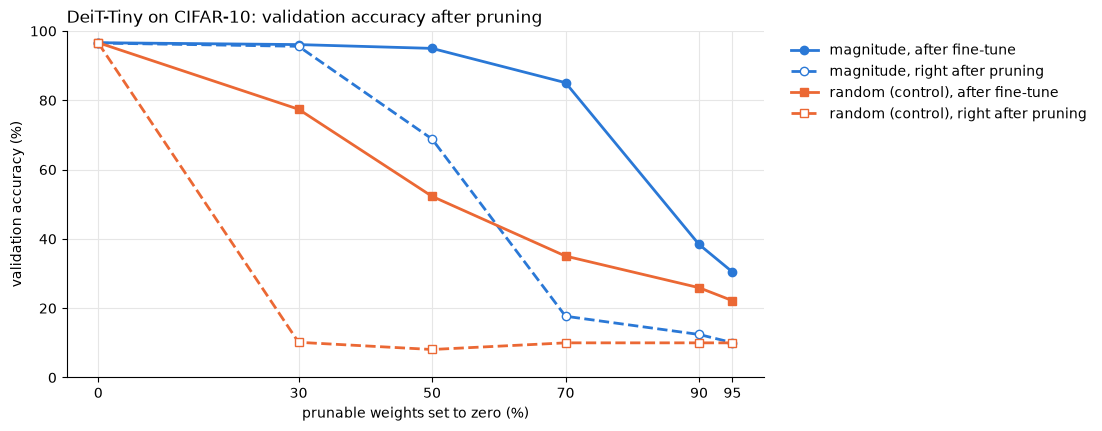

In [9]:
sweep.print_table(results)
sweep.plot_validation(results, METHODS, SPARSITIES, "DeiT-Tiny on CIFAR-10: validation accuracy after pruning")
plt.show()

# What happened (Rule 4)
*Written by the AI assistant on 2026-10-25, at your request ("complete the whole project"). Rewrite it in your own words once you've read it.*

- **What happened:** the base model reached 96.5% validation accuracy (94.6% → 96.1% → 96.5%), clearing PLAN.md's 94% bar with less than half a point gained in epoch 3, so the recipe stayed as it was. The base-model prediction held. Pruning hit much harder than predicted. After the fine-tune, magnitude pruning keeps 96.1% at 30% and 95.0% at 50%, then falls to 85.1% at 70%, 38.4% at 90% and 30.5% at 95%. Random pruning sends the model to chance right after pruning, even at 30%. After the fine-tune it reaches 77.4% at 30% and 22.2% at 95%. The sweep prediction ("within 1 point up to 70%, a few points below at 90–95%") was wrong from 70% on. Every model kept exactly its intended sparsity through the fine-tune.
- **What we learned:** with one-shot unstructured pruning and one recovery epoch, DeiT-Tiny has little spare capacity. Magnitude pruning beats random pruning by 19 to 50 points of validation accuracy between 30% and 70%, so *which* weights are removed matters a great deal.
- **Open questions:** is this fragility a property of ViTs, or of DeiT-Tiny's small size (5.5M parameters, half of ResNet-18's)? Would a longer or gradual fine-tune recover more?